In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Распаковываем архивы с Диска в быструю память Colab
!unzip -q /content/drive/MyDrive/real_tiles.zip -d dataset_real
!unzip -q /content/drive/MyDrive/ai_tiles.zip -d dataset_ai

# Проверяем, что распаковалось
!ls dataset_real
!ls dataset_ai

tiles_256
tiles_256


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

REAL_DIR = 'dataset_real/tiles_256'
AI_DIR = 'dataset_ai/tiles_256'
real_paths = glob.glob(f'{REAL_DIR}/**/*.png', recursive=True)
ai_paths = glob.glob(f'{AI_DIR}/**/*.png', recursive=True)

print(f"Real: {len(real_paths)} файлов")
print(f"AI: {len(ai_paths)} файлов")

# Если выдает 0, значит пути неверные. Измените REAL_DIR и AI_DIR.
all_paths = real_paths + ai_paths
all_labels = [0] * len(real_paths) + [1] * len(ai_paths)

X_train, X_temp, y_train, y_temp = train_test_split(all_paths, all_labels, test_size=0.3, random_state=42, stratify=all_labels)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

Real: 8068 файлов
AI: 7456 файлов


In [ ]:
BATCH_SIZE = 32

def load_and_preprocess(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.cast(img, tf.float32)
    img = tf.keras.applications.resnet_v2.preprocess_input(img)
    return img, label

def create_dataset(paths, labels, is_training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    if is_training:
        ds = ds.shuffle(buffer_size=2000)
        # Аугментация: отражение, яркость, контраст (без поворотов на 90°)
        ds = ds.map(lambda x, y: (tf.image.random_flip_left_right(x), y))
        ds = ds.map(lambda x, y: (tf.image.random_brightness(x, 0.1), y))
        ds = ds.map(lambda x, y: (tf.image.random_contrast(x, 0.9, 1.1), y))
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = create_dataset(X_train, y_train, is_training=True)
val_ds = create_dataset(X_val, y_val)
test_ds = create_dataset(X_test, y_test)

In [ ]:
base_model = ResNet50V2(weights='imagenet', include_top=False, input_shape=(256, 256, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(32, activation='relu')(x)
x = Dropout(0.4)(x)
predictions = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=predictions)
model.compile(optimizer=Adam(learning_rate=1e-4), loss='binary_crossentropy', metrics=['accuracy'])

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

callbacks = [
    EarlyStopping(patience=5, restore_best_weights=True, monitor='val_loss'),
    ModelCheckpoint('/content/drive/MyDrive/best_ai_detector.keras', save_best_only=True, monitor='val_loss')
]

history = model.fit(train_ds, validation_data=val_ds, epochs=15, callbacks=callbacks)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 1/15
340/340 ━━━━━━━━━━━━━━━━━━━━ 125s 258ms/step - accuracy: 0.8247 - loss: 0.4038 - val_accuracy: 0.9407 - val_loss: 0.2046
Epoch 2/15
340/340 ━━━━━━━━━━━━━━━━━━━━ 48s 128ms/step - accuracy: 0.9321 - loss: 0.2161 - val_accuracy: 0.9493 - val_loss: 0.1636
Epoch 3/15
340/340 ━━━━━━━━━━━━━━━━━━━━ 50s 137ms/step - accuracy: 0.9424 - loss: 0.1835 - val_accuracy: 0.9575 - val_loss: 0.1466
Epoch 4/15
340/340 ━━━━━━━━━━━━━━━━━━━━ 50s 131ms/step - accuracy: 0.9473 - loss: 0.1633 - val_accuracy: 0.9601 - val_loss: 0.1400
Epoch 5/15
340/340 ━━━━━━━━━━━━━━━━━━━━ 82s 130ms/step - accuracy: 0.9525 - loss: 0.1512 - val_accuracy: 0.9614 - val_loss: 0.1338
Epoch 6/15
340/340 ━━━━━━━━━━━━━━━━━━━━ 80s 125ms/step - accuracy: 0.9549 - loss: 0.1419 - val_accuracy: 0.9601 - val_loss: 0.1300
Epoch 7/15
340/340 ━━━━━━━━━━━━━━━━━━━━ 50s 133ms/step - accuracy: 0.9553 - loss: 0.

73/73 ━━━━━━━━━━━━━━━━━━━━ 22s 178ms/step
=== ОТЧЕТ ПО КЛАССАМ ===
              precision    recall  f1-score   support

    Real (0)       0.94      0.99      0.96      1211
    Fake (1)       0.98      0.94      0.96      1118

    accuracy                           0.96      2329
   macro avg       0.96      0.96      0.96      2329
weighted avg       0.96      0.96      0.96      2329



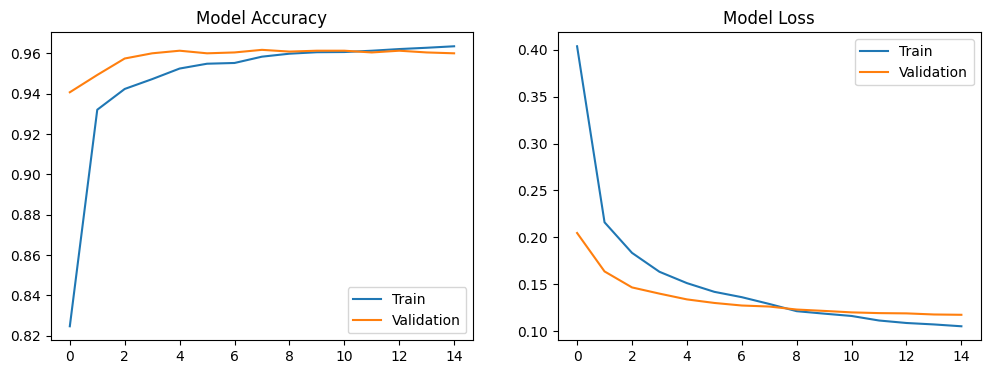

In [ ]:
# Предсказания для тестовой выборки
y_pred_probs = model.predict(test_ds)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()

print("=== ОТЧЕТ ПО КЛАССАМ ===")
print(classification_report(y_test, y_pred, target_names=['Real (0)', 'Fake (1)']))

# Графики
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Model Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Model Loss')
plt.legend()
plt.show()

--- ПОСТРОЕНИЕ CONFUSION MATRIX И ROC ---


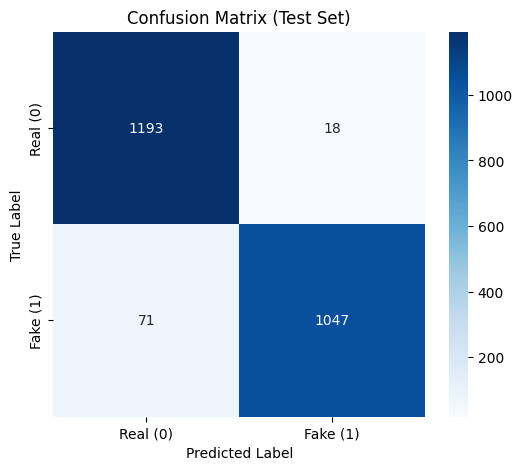

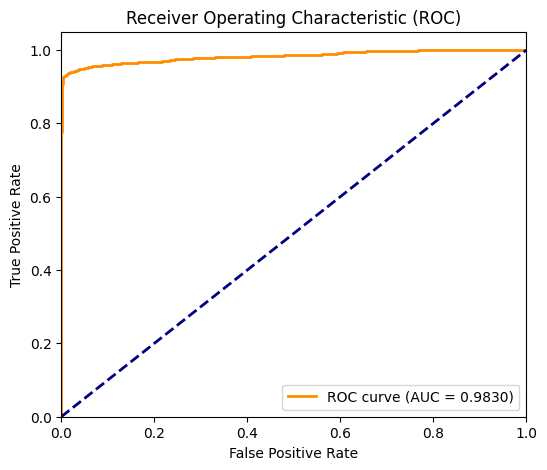


--- ТЕСТ ПО ГЕНЕРАТОРАМ (ТОЧНОСТЬ РАСПОЗНАВАНИЯ ФЕЙКОВ) ---
SD15      : 99.38% (всего фрагментов: 800)
SDXL      : 99.96% (всего фрагментов: 2500)
DDPM      : 100.00% (всего фрагментов: 126)
GAN       : 99.00% (всего фрагментов: 2500)
VAE       : 66.08% (всего фрагментов: 1300)
YANDEXART : 99.57% (всего фрагментов: 230)

--- ТЕСТ НА СЖАТЫХ ДАННЫХ ---


In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc, accuracy_score

# Функция для загрузки картинок (универсальная для PNG и JPG)
def load_img_universal(path, label):
    img = tf.io.read_file(path)
    # try/except нужен на случай битых файлов, но decode_image обычно справляется
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (256, 256))
    img = tf.cast(img, tf.float32)
    img = tf.keras.applications.resnet_v2.preprocess_input(img)
    return img, label

# 1. CONFUSION MATRIX И ROC-КРИВАЯ
print("--- ПОСТРОЕНИЕ CONFUSION MATRIX И ROC ---")
# Берем отложенную тестовую выборку (X_test, y_test)
test_paths = X_test
test_labels = y_test

test_ds = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_ds = test_ds.map(load_img_universal, num_parallel_calls=tf.data.AUTOTUNE).batch(32)

# Получаем вероятности
y_pred_probs = model.predict(test_ds, verbose=0).flatten()
y_pred_classes = (y_pred_probs > 0.5).astype(int)

# Confusion Matrix
cm = confusion_matrix(test_labels, y_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Real (0)', 'Fake (1)'],
            yticklabels=['Real (0)', 'Fake (1)'])
plt.title('Confusion Matrix (Test Set)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# ROC-кривая
fpr, tpr, thresholds = roc_curve(test_labels, y_pred_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()


# 2. ТЕСТ ПО ТИПАМ ГЕНЕРАТОРОВ
print("\n--- ТЕСТ ПО ГЕНЕРАТОРАМ (ТОЧНОСТЬ РАСПОЗНАВАНИЯ ФЕЙКОВ) ---")
generators = ['sd15', 'sdxl', 'ddpm', 'gan', 'vae', 'yandexart']

for gen in generators:
    gen_dir = f'{AI_DIR}/{gen}'
    if not os.path.exists(gen_dir):
        print(f"{gen}: папка не найдена")
        continue

    a_paths = glob.glob(f'{gen_dir}/**/*.png', recursive=True)
    if not a_paths:
        continue

    # Создаем датасет только из фейков этого генератора
    ds = tf.data.Dataset.from_tensor_slices((a_paths, [1]*len(a_paths)))
    ds = ds.map(load_img_universal, num_parallel_calls=tf.data.AUTOTUNE).batch(32)

    preds = model.predict(ds, verbose=0).flatten()
    pred_labels = (preds > 0.5).astype(int)

    # Точность = сколько фейков модель правильно назвала фейками
    acc = accuracy_score([1]*len(a_paths), pred_labels)
    print(f"{gen.upper():<10}: {acc*100:.2f}% (всего фрагментов: {len(a_paths)})")



In [ ]:
!unzip -q /content/drive/MyDrive/real_jpeg_95.zip -d dataset_real_jpeg_95
!unzip -q /content/drive/MyDrive/ai_jpeg_95.zip -d dataset_ai_jpeg_95

!unzip -q /content/drive/MyDrive/real_jpeg_90.zip -d dataset_real_jpeg_90
!unzip -q /content/drive/MyDrive/ai_jpeg_90.zip -d dataset_ai_jpeg_90

!unzip -q /content/drive/MyDrive/real_jpeg_80.zip -d dataset_real_jpeg_80
!unzip -q /content/drive/MyDrive/ai_jpeg_80.zip -d dataset_ai_jpeg_80

In [ ]:
!ls dataset_real_jpeg_90
!ls dataset_ai_jpeg_90

jpeg_90
jpeg_90


In [ ]:
# 3. ТЕСТ НА СЖАТЫХ ВЕРСИЯХ
import glob
import tensorflow as tf
from sklearn.metrics import accuracy_score

print("\n--- ТЕСТ НА СЖАТЫХ ДАННЫХ ---")

def test_compression(real_jpg_dir, ai_jpg_dir, name):
    # Ищем файлы .jpg рекурсивно во всех подпапках
    r_paths = glob.glob(f'{real_jpg_dir}/**/*.jpg', recursive=True)
    a_paths = glob.glob(f'{ai_jpg_dir}/**/*.jpg', recursive=True)

    if not r_paths or not a_paths:
        print(f"{name}: данные не найдены (проверьте пути)")
        return

    paths = r_paths + a_paths
    labels = [0]*len(r_paths) + [1]*len(a_paths)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_img_universal, num_parallel_calls=tf.data.AUTOTUNE).batch(32)

    preds = model.predict(ds, verbose=0)
    pred_labels = (preds > 0.5).astype(int).flatten()

    acc = accuracy_score(labels, pred_labels)
    print(f"{name}: Общая Accuracy = {acc*100:.2f}% (найдено {len(paths)} файлов)")

test_compression('dataset_real_jpeg_95/jpeg_95', 'dataset_ai_jpeg_95/jpeg_95', 'JPEG 95%')
test_compression('dataset_real_jpeg_90/jpeg_90', 'dataset_ai_jpeg_90/jpeg_90', 'JPEG 90%')
test_compression('dataset_real_jpeg_80/jpeg_80', 'dataset_ai_jpeg_80/jpeg_80', 'JPEG 80%')


--- ТЕСТ НА СЖАТЫХ ДАННЫХ ---
JPEG 95%: Общая Accuracy = 96.52% (найдено 15524 файлов)
JPEG 90%: Общая Accuracy = 96.43% (найдено 15524 файлов)
JPEG 80%: Общая Accuracy = 96.24% (найдено 15524 файлов)


# проверка сжатия

In [ ]:
!rm -rf /content/drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
!ls /content/drive/MyDrive/

 ai_jpeg_80.zip   best_ai_detector.keras   real_jpeg_95.zip	     'полина д'
 ai_jpeg_90.zip  'Colab Notebooks'	   real_tiles.zip
 ai_jpeg_95.zip   real_jpeg_80.zip	  'Новый документ (1).gdoc'
 ai_tiles.zip	  real_jpeg_90.zip	  'Новый документ.gdoc'


In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import load_model
from sklearn.metrics import accuracy_score

# 1. Распаковываем все архивы с Диска
print("Распаковка архивов...")
!unzip -q /content/drive/MyDrive/real_tiles.zip -d dataset_real
!unzip -q /content/drive/MyDrive/ai_tiles.zip -d dataset_ai
!unzip -q /content/drive/MyDrive/real_jpeg_95.zip -d dataset_real_jpeg_95
!unzip -q /content/drive/MyDrive/ai_jpeg_95.zip -d dataset_ai_jpeg_95
!unzip -q /content/drive/MyDrive/real_jpeg_90.zip -d dataset_real_jpeg_90
!unzip -q /content/drive/MyDrive/ai_jpeg_90.zip -d dataset_ai_jpeg_90
!unzip -q /content/drive/MyDrive/real_jpeg_80.zip -d dataset_real_jpeg_80
!unzip -q /content/drive/MyDrive/ai_jpeg_80.zip -d dataset_ai_jpeg_80
print("Распаковка завершена!")

# 2. Загружаем модель
MODEL_PATH = '/content/drive/MyDrive/best_ai_detector.keras'
model = load_model(MODEL_PATH)
print("Модель успешно загружена!")

# 3. Восстанавливаем тестовую выборку
REAL_DIR = 'dataset_real/tiles_256'
AI_DIR = 'dataset_ai/tiles_256'

real_paths = glob.glob(f'{REAL_DIR}/**/*.png', recursive=True)
ai_paths = glob.glob(f'{AI_DIR}/**/*.png', recursive=True)

all_paths = real_paths + ai_paths
all_labels = [0] * len(real_paths) + [1] * len(ai_paths)

X_train, X_temp, y_train, y_temp = train_test_split(all_paths, all_labels, test_size=0.3, random_state=42, stratify=all_labels)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

def load_img_universal(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (256, 256))
    img = tf.cast(img, tf.float32)
    img = tf.keras.applications.resnet_v2.preprocess_input(img)
    return img, label

print(f"Данные готовы. В тесте {len(X_test)} фото.")

# 4. Тестирование на сжатие
def get_compressed_paths(original_paths, quality):
    new_paths = []
    for p in original_paths:
        if 'dataset_real' in p:
            new_p = p.replace('dataset_real/tiles_256', f'dataset_real_jpeg_{quality}/jpeg_{quality}')
        else:
            new_p = p.replace('dataset_ai/tiles_256', f'dataset_ai_jpeg_{quality}/jpeg_{quality}')
        new_p = new_p.replace('.png', '.jpg')
        if os.path.exists(new_p):
            new_paths.append(new_p)
    return new_paths

def evaluate_compressed_test_set(paths, labels, name):
    if not paths:
        print(f"{name}: данные не найдены.")
        return
    labels = labels[:len(paths)]
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_img_universal, num_parallel_calls=tf.data.AUTOTUNE).batch(32)
    preds = model.predict(ds, verbose=0)
    pred_labels = (preds > 0.5).astype(int).flatten()
    acc = accuracy_score(labels, pred_labels)
    print(f"{name}: Accuracy = {acc*100:.2f}% (файлов: {len(paths)})")

print(f"--- ЧЕСТНЫЙ ТЕСТ НА СЖАТИЕ ---")
evaluate_compressed_test_set(X_test, y_test, 'PNG (Без сжатия)')

paths_95 = get_compressed_paths(X_test, 95)
evaluate_compressed_test_set(paths_95, y_test, 'JPEG 95%')

paths_90 = get_compressed_paths(X_test, 90)
evaluate_compressed_test_set(paths_90, y_test, 'JPEG 90%')

paths_80 = get_compressed_paths(X_test, 80)
evaluate_compressed_test_set(paths_80, y_test, 'JPEG 80%')

Распаковка архивов...
Распаковка завершена!
Модель успешно загружена!
Данные готовы. В тесте 2329 фото.
--- ЧЕСТНЫЙ ТЕСТ НА СЖАТИЕ ---
PNG (Без сжатия): Accuracy = 95.84% (файлов: 2329)
JPEG 95%: Accuracy = 95.96% (файлов: 2329)
JPEG 90%: Accuracy = 95.84% (файлов: 2329)
JPEG 80%: Accuracy = 95.75% (файлов: 2329)


Всего картинок: 15524
94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Начинаем обучение мультиклассовой модели...
Epoch 1/15
389/389 ━━━━━━━━━━━━━━━━━━━━ 101s 229ms/step - accuracy: 0.7084 - loss: 0.9067 - val_accuracy: 0.8744 - val_loss: 0.4332
Epoch 2/15
389/389 ━━━━━━━━━━━━━━━━━━━━ 44s 112ms/step - accuracy: 0.8673 - loss: 0.4545 - val_accuracy: 0.9066 - val_loss: 0.3171
Epoch 3/15
389/389 ━━━━━━━━━━━━━━━━━━━━ 81s 110ms/step - accuracy: 0.8964 - loss: 0.3497 - val_accuracy: 0.9224 - val_loss: 0.2688
Epoch 4/15
389/389 ━━━━━━━━━━━━━━━━━━━━ 83s 114ms/step - accuracy: 0.9154 - loss: 0.2916 - val_accuracy: 0.9298 - val_loss: 0.2430
Epoch 5/15
389/389 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - accuracy: 0.9257 - loss: 0.2490 - val_accuracy: 0.9330 - val_loss: 0.2297
Epoch 6/15
389/389 ━━━━━━━━━━━━━━━━━━━━ 83s 112ms/step - accuracy: 0.9332 - loss: 0.2266 - val_accuracy: 0.9378 - val_loss: 0.2146
Epoch 7/15
389/389 ━━━━━━━━━━━━━━━━━━━━ 44s 113ms/step - accuracy: 0.9374 - loss: 0.2069 - val_a

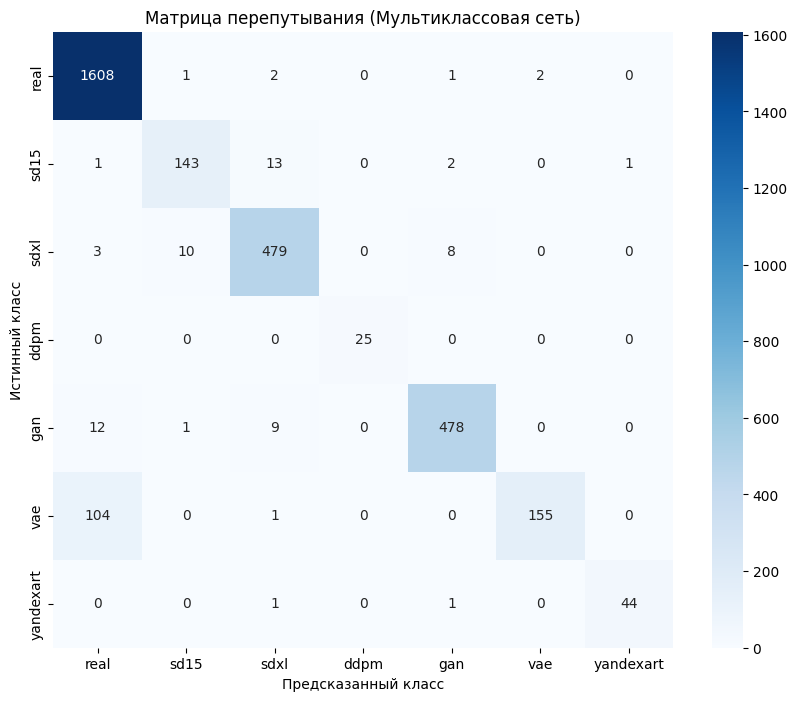

              precision    recall  f1-score   support

        real       0.93      1.00      0.96      1614
        sd15       0.92      0.89      0.91       160
        sdxl       0.95      0.96      0.95       500
        ddpm       1.00      1.00      1.00        25
         gan       0.98      0.96      0.97       500
         vae       0.99      0.60      0.74       260
   yandexart       0.98      0.96      0.97        46

    accuracy                           0.94      3105
   macro avg       0.96      0.91      0.93      3105
weighted avg       0.95      0.94      0.94      3105



In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Распаковка
if not os.path.exists('dataset_real'):
    !unzip -q real_tiles.zip -d dataset_real
    !unzip -q ai_tiles.zip -d dataset_ai
    print("Архивы распакованы.")

# 2. Классы (Real + 6 генераторов)
class_names = ['real', 'sd15', 'sdxl', 'ddpm', 'gan', 'vae', 'yandexart']
class_indices = {name: i for i, name in enumerate(class_names)}

all_paths = []
all_labels = []

# Собираем реальные
for p in glob.glob('dataset_real/tiles_256/**/*.png', recursive=True):
    all_paths.append(p)
    all_labels.append(class_indices['real'])

# Собираем фейки по папкам
for gen in class_names[1:]:
    for p in glob.glob(f'dataset_ai/tiles_256/{gen}/**/*.png', recursive=True):
        all_paths.append(p)
        all_labels.append(class_indices[gen])

print(f"Всего картинок: {len(all_paths)}")

# 3. Делим на Train/Val (80/20)
X_train, X_val, y_train, y_val = train_test_split(
    all_paths, all_labels, test_size=0.2, stratify=all_labels, random_state=42
)

# 4. Датасет с one-hot метками
def load_multiclass(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.cast(img, tf.float32)
    img = tf.keras.applications.resnet_v2.preprocess_input(img)
    return img, tf.one_hot(label, depth=7)

BATCH_SIZE = 32
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).map(load_multiclass).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).map(load_multiclass).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# 5. Собираем модель
base_model = ResNet50V2(weights='imagenet', include_top=False, input_shape=(256, 256, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.4)(x)
preds = Dense(7, activation='softmax')(x)

model_multi = Model(inputs=base_model.input, outputs=preds)
model_multi.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 6. Обучение с EarlyStopping
early_stop = EarlyStopping(patience=3, restore_best_weights=True, monitor='val_loss')
print("Начинаем обучение мультиклассовой модели...")
history = model_multi.fit(train_ds, validation_data=val_ds, epochs=15, callbacks=[early_stop])

# 7. Построение матрицы ошибок
print("Построение матрицы ошибок...")
y_pred_probs = model_multi.predict(val_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_val, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Матрица перепутывания (Мультиклассовая сеть)')
plt.ylabel('Истинный класс')
plt.xlabel('Предсказанный класс')
plt.show()

print(classification_report(y_val, y_pred, target_names=class_names))

In [ ]:
model_multi.save('/content/drive/MyDrive/model_multi.keras')

print("Готово! Файл model_multi.keras появился в корне вашего Google Диска.")

Готово! Файл model_multi.keras появился в корне вашего Google Диска.


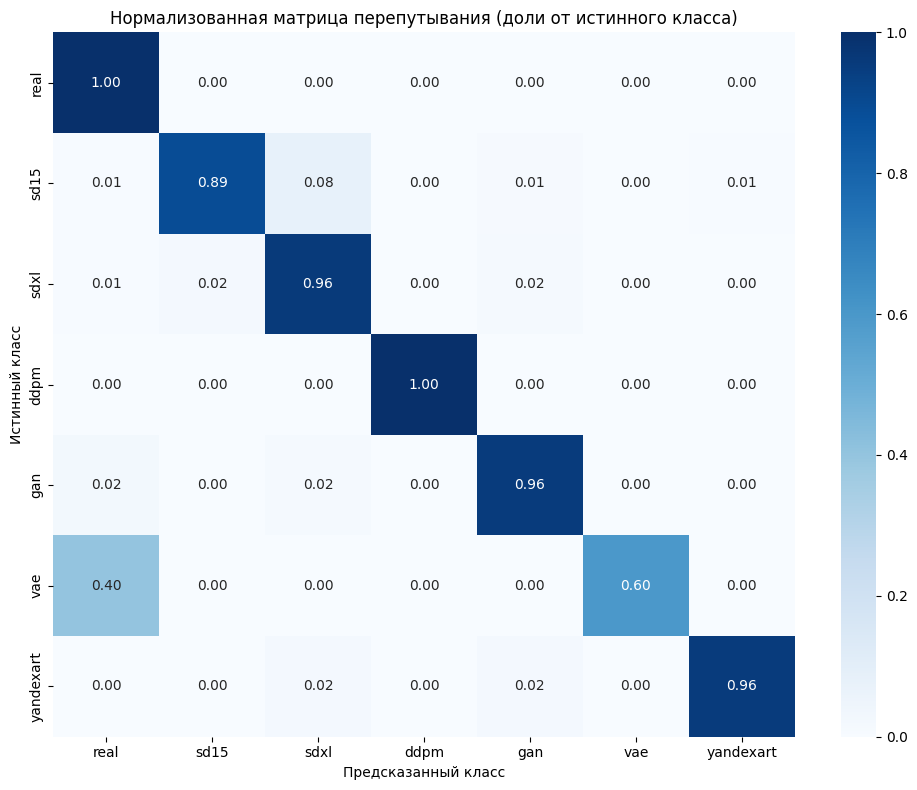

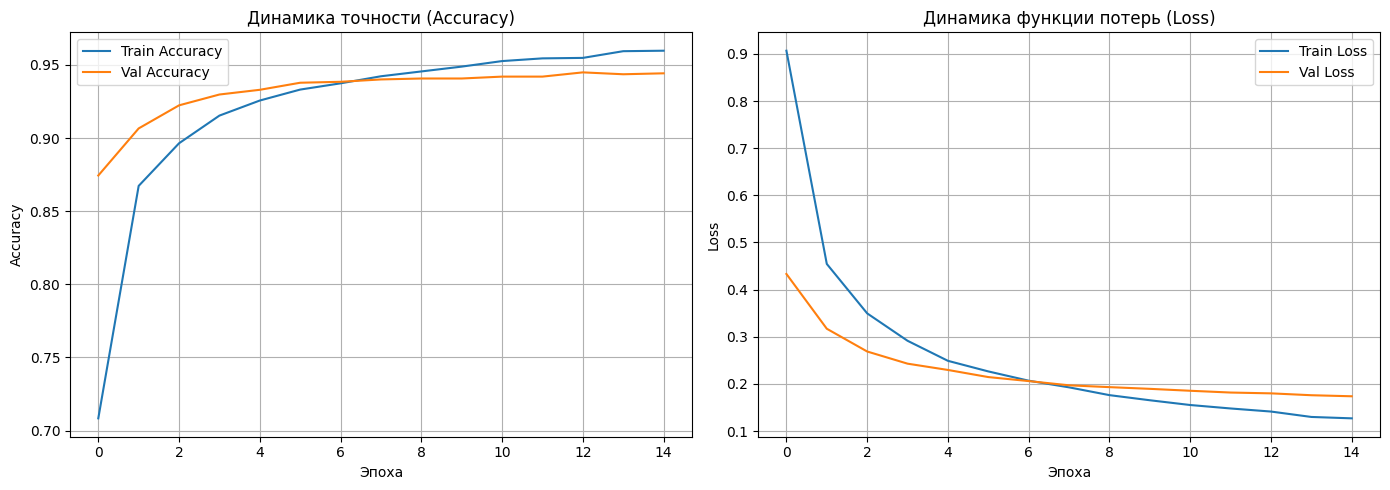

Все графики в высоком разрешении (300 dpi) и данные сохранены на Google Диск!


In [ ]:
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

save_dir = '/content/drive/MyDrive'

# 1. Нормализованная матрица перепутывания (в долях / процентах по строкам)
# Показывает точный % попаданий для каждого генератора независимо от размера выборки
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Нормализованная матрица перепутывания (доли от истинного класса)')
plt.ylabel('Истинный класс')
plt.xlabel('Предсказанный класс')
plt.tight_layout()
plt.savefig(f'{save_dir}/confusion_matrix_norm.png', dpi=300)
plt.show()

# 2. Графики обучения (Loss и Accuracy)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['accuracy'], label='Train Accuracy')
ax1.plot(history.history['val_accuracy'], label='Val Accuracy')
ax1.set_title('Динамика точности (Accuracy)')
ax1.set_xlabel('Эпоха')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

ax2.plot(history.history['loss'], label='Train Loss')
ax2.plot(history.history['val_loss'], label='Val Loss')
ax2.set_title('Динамика функции потерь (Loss)')
ax2.set_xlabel('Эпоха')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.savefig(f'{save_dir}/training_curves.png', dpi=300)
plt.show()

# 3. Сохраняем сырые предсказания и историю обучения в JSON
results_data = {
    'class_names': class_names,
    'history': history.history,
    'y_val': [int(x) for x in y_val],
    'y_pred': [int(x) for x in y_pred]
}
with open(f'{save_dir}/experiment_results.json', 'w') as f:
    json.dump(results_data, f)

print("Все графики в высоком разрешении (300 dpi) и данные сохранены на Google Диск!")
